In [1]:
# Reference: https://herbie.readthedocs.io/en/stable/gallery/bonus_notebooks/time-height.html
from functions import *
from herbie import FastHerbie, HerbieLatest
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import numpy as np

# Define the points of interest
# [Fort Collins, Erie]
points = pd.DataFrame({"longitude": [-105.082396, -80.172745], 
                       "latitude": [40.548843, 42.083850],
                       })



In [9]:
# https://herbie.readthedocs.io/en/stable/gallery/noaa_models/hrrr.html
H = HerbieLatest(
    model="hrrr",
    product="sfc",
    fxx=4,

)
t2m_ds = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
               )

# t2m_ds
H.inventory("APCP")
# H.xarray("PRATE", backend_kwargs={'decode_times':False}
#                )


💔 Did not find ┊ model=hrrr ┊ product=sfc ┊ 2024-Dec-27 19:00 UTC F04
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Dec-27 18:00 UTC F04 ┊ GRIB2 @ aws ┊ IDX @ aws


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
83,84,63456111,63982546.0,63456111-63982546,2024-12-27 18:00:00,2024-12-27 22:00:00,APCP,surface,0-4 hour acc fcst,:APCP:surface:0-4 hour acc fcst
89,90,64403339,65035972.0,64403339-65035972,2024-12-27 18:00:00,2024-12-27 22:00:00,APCP,surface,3-4 hour acc fcst,:APCP:surface:3-4 hour acc fcst


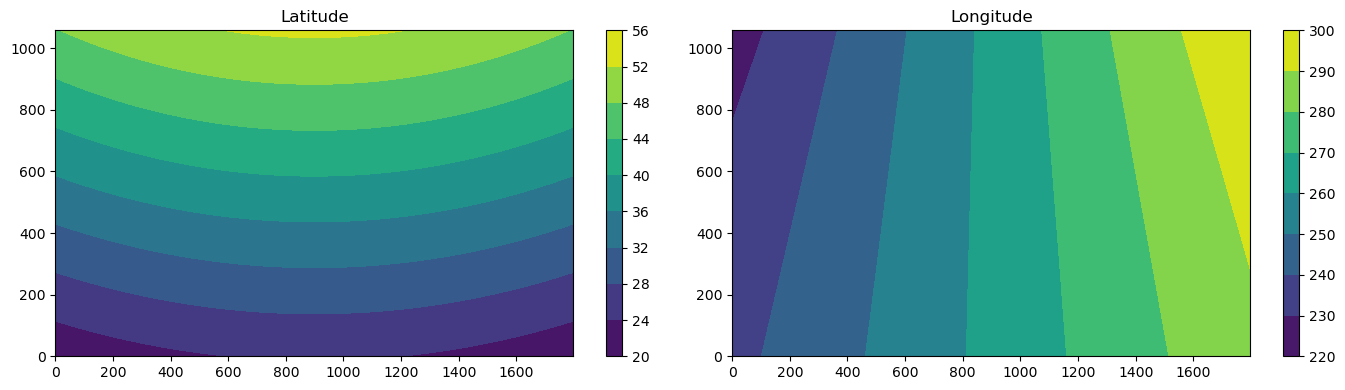

In [10]:
# Create figure and subplots
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 4))

# First subplot - Latitude
im1 = ax1.contourf(t2m_ds.latitude)
ax1.set_title('Latitude')
plt.colorbar(im1, ax=ax1)

# Second subplot - Longitude 
im2 = ax2.contourf(t2m_ds.longitude)
ax2.set_title('Longitude')
plt.colorbar(im2, ax=ax2)

# Adjust layout to prevent overlap
plt.tight_layout()

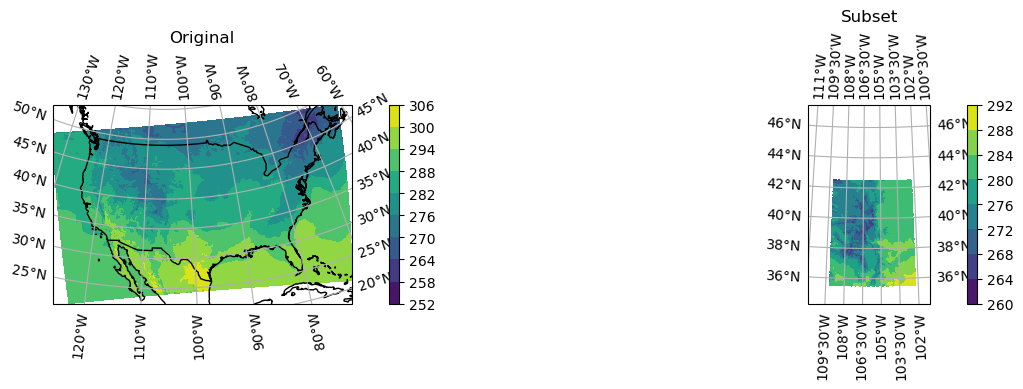

In [13]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Create AzimuthalEquidistant projection
proj = ccrs.AzimuthalEquidistant(central_longitude=-105.7, central_latitude=39)

# Create figure and subplots with projection
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 4),
                              subplot_kw={'projection': proj})

# First subplot - Original data
im1 = ax1.contourf(t2m_ds.longitude.values, t2m_ds.latitude.values, t2m_ds['t2m'].values,
                   transform=ccrs.PlateCarree())
ax1.set_title('Original')
ax1.coastlines()
ax1.add_feature(cfeature.BORDERS)
ax1.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
plt.colorbar(im1, ax=ax1)

# Second subplot - Subset data
subset = sel_region(t2m_ds['t2m'], [39, 360-105.7], 7)
im2 = ax2.contourf(subset.longitude.values, subset.latitude.values, subset.values,
                   transform=ccrs.PlateCarree())
ax2.set_title('Subset')
ax2.coastlines()
ax2.add_feature(cfeature.BORDERS)
ax2.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
plt.colorbar(im2, ax=ax2)

plt.tight_layout()

# Generate a time series

In [14]:
# https://herbie.readthedocs.io/en/stable/gallery/noaa_models/hrrr.html
H = FastHerbie(
    [get_latest_forecast_cycle()],
    model="hrrr",
    product="sfc",
    fxx=list(range(6, 31)),
)

points = pd.DataFrame({"longitude": [-105.082396, -80.172745], # [Fort Collins, Erie]
                       "latitude": [40.548843, 42.083850],
                       })

t2m_ds = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
                  ).herbie.pick_points(points, method="nearest")

t2m_ds

t2m_ds = (t2m_ds['t2m'] - 273.15) * 1.8 + 32

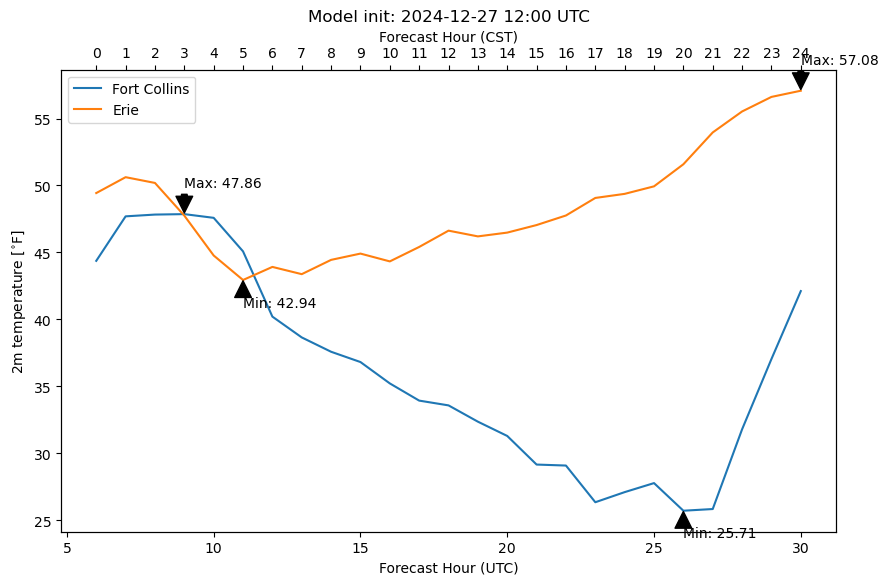

In [15]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {get_latest_forecast_cycle().strftime('%Y-%m-%d %H:%M')} UTC")

fort_collins = t2m_ds.sel(point=0).values
city2 = t2m_ds.sel(point=1).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,31), fort_collins, label='Fort Collins')
ax1.plot(np.arange(6,31), city2, label='Erie')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel(r'2m temperature [$^{\circ}$F]')

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,31))
ax2.set_xticklabels([str(h-6) for h in range(6,31)])
ax2.set_xlabel('Forecast Hour (CST)')

# Annotate max and min for Fort Collins
max_fc = np.max(fort_collins)
min_fc = np.min(fort_collins)
max_fc_idx = np.argmax(fort_collins)
min_fc_idx = np.argmin(fort_collins)

plt.annotate(f'Max: {max_fc:.2f}', xy=(max_fc_idx + 6, max_fc), xytext=(max_fc_idx + 6, max_fc + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_fc:.2f}', xy=(min_fc_idx + 6, min_fc), xytext=(min_fc_idx + 6, min_fc - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))

# Annotate max and min for Wichita Falls
max_wf = np.max(city2)
min_wf = np.min(city2)
max_wf_idx = np.argmax(city2)
min_wf_idx = np.argmin(city2)

plt.annotate(f'Max: {max_wf:.2f}', xy=(max_wf_idx + 6, max_wf), xytext=(max_wf_idx + 6, max_wf + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_wf:.2f}', xy=(min_wf_idx + 6, min_wf), xytext=(min_wf_idx + 6, min_wf - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))


# Add legend
ax1.legend()

plt.show()

## Precip

# To DO: Figure out how to correctly zero the total precip (ie, if it's snowing prior to midnight, I need to remove that precip from the tp). Also, I realized I'm pulling the incorrect model forecasts since the time zone changed. Automate this? Maybe a package which knows the time zone based on coordinates. Finally, change the second plot axis to represent the change in time zone

In [16]:
H = FastHerbie(
    [get_latest_forecast_cycle()],
    model="hrrr",
    product="sfc",
    fxx=list(range(6, 31)),
)
H

In [17]:
# Load in the data
H = FastHerbie(
    [get_latest_forecast_cycle()],
    model="hrrr",
    product="sfc",
    fxx=list(range(6, 31)),
)
                
tp = H.xarray("APCP", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest"
                                   )['tp']
tp = tp * 0.0393701  # Convert mm (1 kg m^-2 = 1 mm) to inches
tp


<xarray.DataArray 'tp' (step: 25, point: 2)> Size: 200B
array([[0.        , 0.        ],
       [0.        , 0.        ],
       [0.        , 0.        ],
       [0.        , 0.        ],
       [0.        , 0.        ],
       [0.        , 0.        ],
       [0.        , 0.        ],
       [0.        , 0.        ],
       [0.        , 0.01614174],
       [0.        , 0.02519686],
       [0.        , 0.02519686],
       [0.        , 0.02559057],
       [0.        , 0.02559057],
       [0.        , 0.02559057],
       [0.        , 0.02559057],
       [0.        , 0.02716537],
       [0.        , 0.03740159],
       [0.        , 0.04488191],
       [0.        , 0.04488191],
       [0.        , 0.04527561],
       [0.        , 0.04527561],
       [0.        , 0.04527561],
       [0.        , 0.04527561],
       [0.        , 0.04527561],
       [0.        , 0.04527561]], dtype=float32)
Coordinates:
    time                 int64 8B 1735300800
  * step                 (step) float64 200B 6.0 7.0 8.0 9.0 ... 28.0 29.0 30.0
    surface              float64 8B 0.0
    latitude             (point) float64 16B 40.55 42.09
    longitude            (point) float64 16B 254.9 279.8
    valid_time           (step) float64 200B 1.735e+09 1.735e+09 ... 1.735e+09
    gribfile_projection  object 8B None
    point_grid_distance  (point) float64 16B 0.9413 0.4454
    point_longitude      (point) float64 16B -105.1 -80.17
    point_latitude       (point) float64 16B 40.55 42.08
Dimensions without coordinates: point

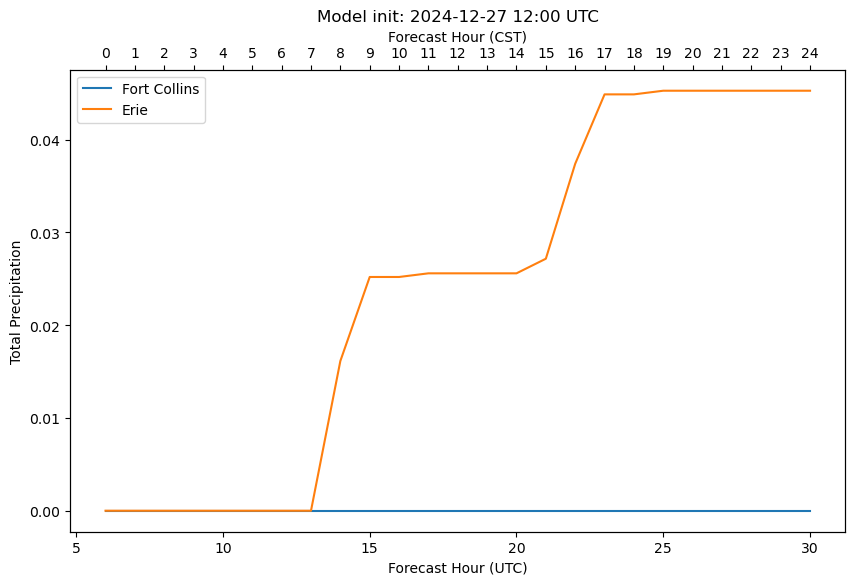

In [18]:

# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {get_latest_forecast_cycle().strftime('%Y-%m-%d %H:%M')} UTC")

fort_collins = tp.sel(point=0).values
city2 = tp.sel(point=1).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,31), fort_collins, label='Fort Collins')
ax1.plot(np.arange(6,31), city2, label='Erie')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel('Total Precipitation')

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,31))
ax2.set_xticklabels([str(h-6) for h in range(6,31)])
ax2.set_xlabel('Forecast Hour (CST)')

# Add legend
ax1.legend()

plt.show()


# TO DO: convert tp from Kg per square meter to inches. Potentially 0.039370079003585

# Add NBM

In [19]:
# dates = pd.date_range("2024-11-21 18:00", periods=1, freq="1h")
today = pd.Timestamp.now().date()
dates = pd.DatetimeIndex([pd.Timestamp(f"{today} 18:00")])

H = FastHerbie(dates, model="nbm", fxx=list(range(6, 31)), product="co")
H.inventory(":TMP:2 m above ground:.*fcst:nan")

points = pd.DataFrame({"longitude": [-105.082396, -80.172745], # [Fort Collins, Erie]
                       "latitude": [40.548843, 42.083850],
                       })

ds = H.xarray(":TMP:2 m above ground:.*fcst:nan", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest")

t2m_ds = (ds['t2m'] - 273.15) * 1.8 + 32

👨🏻‍🏭 Created directory: [/Users/jglarson/data/nbm/20241227]


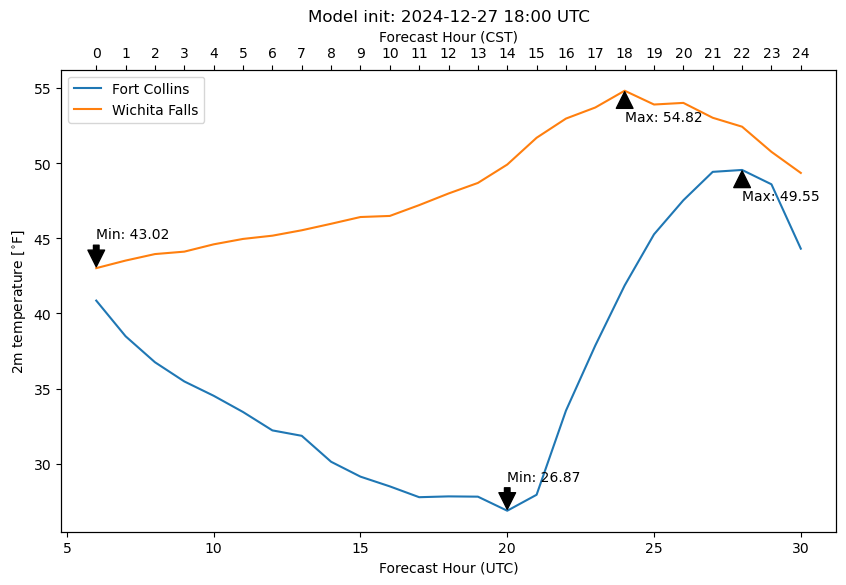

In [20]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {dates[0].strftime('%Y-%m-%d %H:%M')} UTC")

fort_collins = t2m_ds.sel(point=0).values
city2 = t2m_ds.sel(point=1).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,31), fort_collins, label='Fort Collins')
ax1.plot(np.arange(6,31), city2, label='Wichita Falls')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel(r'2m temperature [$^{\circ}$F]')

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,31))
ax2.set_xticklabels([str(h-6) for h in range(6,31)])
ax2.set_xlabel('Forecast Hour (CST)')

# Annotate max and min for Fort Collins
max_fc = np.max(fort_collins)
min_fc = np.min(fort_collins)
max_fc_idx = np.argmax(fort_collins)
min_fc_idx = np.argmin(fort_collins)

plt.annotate(f'Max: {max_fc:.2f}', xy=(max_fc_idx + 6, max_fc), xytext=(max_fc_idx + 6, max_fc - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_fc:.2f}', xy=(min_fc_idx + 6, min_fc), xytext=(min_fc_idx + 6, min_fc + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))

# Annotate max and min for Wichita Falls
max_wf = np.max(city2)
min_wf = np.min(city2)
max_wf_idx = np.argmax(city2)
min_wf_idx = np.argmin(city2)

plt.annotate(f'Max: {max_wf:.2f}', xy=(max_wf_idx + 6, max_wf), xytext=(max_wf_idx + 6, max_wf - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_wf:.2f}', xy=(min_wf_idx + 6, min_wf), xytext=(min_wf_idx + 6, min_wf + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))


# Add legend
ax1.legend()

plt.show()

# To Do: Generate verificatoin statistics to know what model is good and bad

In [21]:
import requests
import pandas as pd
import datetime as dt

import requests
import pandas as pd
import datetime as dt

import matplotlib.pyplot as plt

def plot_noaa_metar(station="KFNL",
    # Calculate time range (UTC)
    end = dt.datetime.utcnow()
    start = end - dt.timedelta(days=days)
    start_str = start.isoformat() + "Z"
    end_str = end.isoformat() + "Z"
    
    # NOAA API endpoint for station METAR observations
    url = (
        f"https://api.weather.gov/stations/{station}/observations"
        f"?start={start_str}&end={end_str}"
    )

    # Fetch data
    r = requests.get(url)
    r.raise_for_status()
    raw_data = r.json()

    # Parse METAR observations
    records = []
    for feature in raw_data.get("features", []):
        props = feature.get("properties", {})
        observation_time = props.get("timestamp")
        if None in (observation_time, temperature_c, wind_speed_mps):
            continue
        records.append({
            "time": pd.to_datetime(observation_time),
            "temp_F": temperature_c * 9/5 + 32,
            "wind_speed_knots": wind_speed_mps * 1.94384,  # 1 m/s = 1.94384 knots
        temperature_c = props.get("temperature", {}).get("value")  # Celsius
        wind_speed_mps = props.get("windSpeed", {}).get("value")   # m/s
        precip_mm = props.get("precipitationLast3Hours", {}).get("value")  # mm
        # Some METAR reports may not have all fields,
        if None in (observation_
            continue
        records.append({
    
           
            "wind_speed_knots": wind_speed_mps * 1.94384,  # 1 m/s
     


    # Create DataFrame
    df = pd.DataFrame(r

        print(f"
        return

    df["da


    daily = df.groupby("date").agg(

        "wind_speed_knots": "max",
        "precip_in": "sum"
    })
    plt.suptitle(f"NOAA METAR Daily Stats for {station} (Last {days} Days)")
    plt.tight_layout()

# Example usage:
# plot_noaa_metar(station="KFNL", days=7)    plt.show()

    axes[3].set_xlabel("Date")
    daily["Total Precip (in)"].plot(ax=axes[3], marker="o", ylabel="Precip (in)", legend=True)
    daily["Max Wind (kts)"].plot(ax=axes[2], marker="o", ylabel="Wind (kts)", legend=True)
    daily["Max Temp (F)"].plot(ax=axes[1], marker="o", ylabel="Max Temp (F)", legend=True)
    daily["Min Temp (F)"].plot(ax=axes[0], marker="o", ylabel="Min Temp (F)", legend=True)
    da
    
    # Plot
    fig, axes = plt.subplots(nrows=
    daily["Min Temp (F)"].plot(ax=axes[0], marker="o", ylabel="Min Temp (F)", legend=True)
    daily["Max Temp (F)"].
    daily["Max Wind (kts)"].plot(ax=axes[2], marker="o

    axes[3].set_
    plt.suptitle(f"NOAA METAR Daily Stats for {station} (Last {days} Days)"
    plt.tight_layout()
    plt.show()

# Example usage:
# plot_noaa_metar(station="KFNL", days=7))xlabel("Date")    daily["Total Precip (in)"].plot(ax=axes[3], marker="o", ylabel="Precip (in)", legend=True)", ylabel="Wind (kts)", legend=True)plot(ax=axes[1], marker="o", ylabel="Max Temp (F)", legend=True)4, ncols=1, figsize=(8, 8), sharex=True)ily.columns = ["Min Temp (F)", "Max Temp (F)", "Max Wind (kts)", "Total Precip (in)"]        "temp_F": ["min", "max"],{    # Group by date, compute daily statste"] = df["time"].dt.dateNo valid data found for station {station} in that period.")    if df.empty:ecords)        })       "precip_in": precip_mm * 0.0393701 if precip_mm else 0.0 = 1.94384 knots "temp_F": temperature_c * 9/5 + 32,        "time": pd.to_datetime(observation_time),time, temperature_c, wind_speed_mps): so skip incomplete days=7):import matplotlib.pyplot matplo

def plot_noaa_metar(station="KFNL",
    # Calculate time range (UTC)
    end = dt.datetime.utcnow()
    start = end - dt.timedelta(days=days)
    start_str = start.isoformat() + "Z"
    end_str = end.isoformat() + "Z"
    
    # NOAA API endpoint for station METAR observations
    url = (
        f"https://api.weather.gov/stations/{station}/observations"
        f"?start={start_str}&end={end_str}"
    )

    # Fetch data
    r = requests.get(url)
    r.raise_for_status()
    raw_data = r.json()

    # Parse METAR observations
    records = []
    for feature in raw_data.get("features", []):
        props = feature.get("properties", {})
        observation_time = props.get("timestamp")
        temperature_c = props.get("temperature", {}).get("value")  # Celsius
        wind_speed_mps = props.get("windSpeed", {}).get("value")   # m/s
        precip_mm = props.get("precipitationLast3Hours", {}).get("value")  # mm
        # Some METAR reports may not have all fields, so skip incomplete
    # Calculate time range (UTC)
    end = dt.datetime.utcnow()
    start_str = start.isoformat() +
    
    url = (
        f"https://api.weather.gov/stations/{station}/observations"
     

    # Fetch data
    r.raise_for_status()
    raw_data = r.json()

    # Parse META
    for feature in raw_data.get("features", [
        observation_time = props.get("timestamp")
        te


    df["date"] = df["time"].dt.date

    daily = df.groupby("date").agg({
        "temp_F": ["min", "max"],
        "wind_speed_knots"
    })
    
    # Plot
    fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(8, 8), sharex=True)
    daily.columns = ["Min Temp (F)", "Max Temp (F)", "Max Wind (kts)", "Total Precip (in)"]: "max",
        "precip_in": "sum"
    # Group by date, compute daily stats        return

    if df.empty:
        print(f"No valid data found for station {station} in that period.")
    df = pd.DataFrame(records)
    # Create DataFramemperature_c = props.get("temperature", {}).get("value")  #
        }) Cel
        if None in (observation_time, temperature_c, wind_speed_mps):
            continue
            "precip_in": precip_mm * 0.0393701 if precip_mm else 0.0
        records.append({
            "wind_speed_knots": wind_speed_mps * 1.94384,  # 1 m/s = 1.94384 knots
            "temp_F": temperature_c * 9/5 + 32,
            "time": pd.to_datetime(observation_time),
        precip_mm = props.get("precipitationLast3Hours", {}).get("value")  # mm
        # Some METAR reports may not have all fields, so skip incompletesius
        wind_speed_mps = props.get("windSpeed", {}).get("value")   # m/s]):
        props = feature.get("properties", {})R observations
    records = []
    r = requests.get(url)   f"?start={start_str}&end={end_str}"
    )
    # NOAA API endpoint for station METAR observations "Z"
    end_str = end.isoformat() + "Z"
    start = end - dt.timedelta(days=days) days=7):
def plot_noaa_metar(station="KFNL", days=7):tlib.pyplot as as plt plt

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3730425509.py, line 13)

In [18]:
import re

# Example multiline string, but in practice you might read from a file or other source:
metar_text = """\
KPDX 280253Z 15008KT 9SM -RA SCT018 BKN023 OVC039 10/07 A2974 RMK AO2 SLP071 P0004 60015 T01000072 58014
KPDX 280153Z 16007KT 8SM RA FEW035 OVC048 10/07 A2975 RMK AO2 SLP072 P0008 T01000072
KPDX 280053Z 20011G19KT 10SM -RA FEW017 BKN050 OVC080 11/08 A2978 RMK AO2 SLP085 P0003 T01060078
KPDX 272353Z 20009KT 8SM RA FEW020 BKN055 OVC080 11/08 A2978 RMK AO2 RAB29 SLP085 P0001 60002 T01060078 10117 20106 50001
KPDX 272321Z 21010G19KT 10SM FEW021 BKN045 OVC110 11/08 A2979 RMK AO2 T01110078
KPDX 272253Z 20009KT 10SM FEW018 BKN027 OVC120 11/08 A2978 RMK AO2 SLP085 T01110078
KPDX 271853Z 21012KT 10SM FEW015 BKN049 BKN060 12/08 A2974 RMK AO2 SLP069 T01170083
KPDX 271753Z 19011G19KT 10SM SCT012 BKN037 11/08 A2971 RMK AO2 RAB10E47 SLP059 P0000 60004 T01060078 10106 20072 51030
KPDX 271748Z 19010G20KT 10SM SCT012 BKN037 11/08 A2971 RMK AO2 RAB10E47 P0000
KPDX 271701Z 20013G20KT 9SM SCT012 BKN029 BKN037 10/07 A2967 RMK AO2 T01000072
KPDX 271653Z 20012G18KT 10SM BKN012 BKN029 10/07 A2966 RMK AO2 RAB22E49 SLP044 P0000 T01000072
"""

def parse_metar_line(line):
    """
    Given a line like:
      KPDX 280253Z 15008KT 9SM -RA SCT018 ... T01000072 ...
    parse out:
      - date (day of month)
      - time (UTC, from HHMM in DDHHMMZ)
      - wind direction, speed, gust (if any)
      - temperature in Celsius (from the 'Txxxxyyyy' group)
    Return a dict with these fields.
    """

    # Split line into tokens
    tokens = line.split()

    result = {
        'station': None,
        'day': None,
        'time_utc': None,
        'wind_dir': None,
        'wind_speed_kt': None,
        'wind_gust_kt': None,
        'temperature_c': None,
    }

    # 1) Station (e.g. KPDX)
    if len(tokens) > 0:
        result['station'] = tokens[0]

    # 2) Date/time group (e.g. 280253Z)
    if len(tokens) > 1:
        dt_match = re.match(r"^(\d{2})(\d{2})(\d{2})Z$", tokens[1])
        if dt_match:
            day_str = dt_match.group(1)  # '28'
            hh = dt_match.group(2)       # '02'
            mm = dt_match.group(3)       # '53'
            result['day'] = day_str
            result['time_utc'] = f"{hh}:{mm}Z"

    # 3) Wind group: something like 15008KT or 20011G19KT
    # We'll look for the first token that matches that pattern
    wind_pattern = re.compile(r"^(\d{3})(\d{2})(G(\d{1,2}))?KT$")
    for tok in tokens:
        m = wind_pattern.match(tok)
        if m:
            # Direction is group(1), speed is group(2), gust is group(4)
            try:
                result['wind_dir'] = int(m.group(1))
                result['wind_speed_kt'] = int(m.group(2))
                if m.group(4):
                    result['wind_gust_kt'] = int(m.group(4))
            except ValueError:
                pass
            break

    # 4) Temperature from the T-group (e.g. T01000072)
    #    Format is TsTTTsddd, where:
    #       T = literal 'T'
    #       s = sign bit for temperature (0 => +, 1 => -)
    #       TTT = temperature in tenths of °C
    #       s = sign bit for dewpoint (0 => +, 1 => -)
    #       ddd = dewpoint in tenths of °C
    #
    #    Example: T01000072
    #      'T'  -> literal T
    #      '0'  -> temp sign bit (0 => +)
    #      '100'-> temperature in tenths => 10.0°C
    #      '0'  -> dewpoint sign bit (0 => +)
    #      '072'-> dewpoint in tenths => 7.2°C

    t_pattern = re.compile(r"^T(\d)(\d{3})(\d)(\d{3})$")
    for tok in tokens:
        m = t_pattern.match(tok)
        if m:
            # Sign bit for temperature
            temp_sign_bit = int(m.group(1))
            # Temperature (in tenths of °C)
            temp_tenths = int(m.group(2))

            # Convert to actual Celsius with sign
            if temp_sign_bit == 1:
                temperature_c = -temp_tenths / 10.0
            else:
                temperature_c = temp_tenths / 10.0

            result['temperature_c'] = temperature_c
            break  # Stop after parsing the first T-group found

    return result


def main():
    # We split the multiline string into individual lines (each is one METAR)
    lines = metar_text.strip().splitlines()

    # Parse each line
    observations = []
    for line in lines:
        parsed = parse_metar_line(line.strip())
        observations.append(parsed)

    # Print results
    for i, obs in enumerate(observations, start=1):
        print(f"--- Obs #{i} ---")
        print(f"  Station: {obs['station']}")
        print(f"  Day: {obs['day']}")
        print(f"  Time (UTC): {obs['time_utc']}")
        print(f"  Wind Dir (°): {obs['wind_dir']}")
        print(f"  Wind Speed (kt): {obs['wind_speed_kt']}")
        if obs['wind_gust_kt']:
            print(f"  Wind Gust (kt): {obs['wind_gust_kt']}")
        print(f"  Temperature (C): {obs['temperature_c']}\n")


if __name__ == "__main__":
    main()


--- Obs #1 ---
  Station: KPDX
  Day: 28
  Time (UTC): 02:53Z
  Wind Dir (°): 150
  Wind Speed (kt): 8
  Temperature (C): 10.0

--- Obs #2 ---
  Station: KPDX
  Day: 28
  Time (UTC): 01:53Z
  Wind Dir (°): 160
  Wind Speed (kt): 7
  Temperature (C): 10.0

--- Obs #3 ---
  Station: KPDX
  Day: 28
  Time (UTC): 00:53Z
  Wind Dir (°): 200
  Wind Speed (kt): 11
  Wind Gust (kt): 19
  Temperature (C): 10.6

--- Obs #4 ---
  Station: KPDX
  Day: 27
  Time (UTC): 23:53Z
  Wind Dir (°): 200
  Wind Speed (kt): 9
  Temperature (C): 10.6

--- Obs #5 ---
  Station: KPDX
  Day: 27
  Time (UTC): 23:21Z
  Wind Dir (°): 210
  Wind Speed (kt): 10
  Wind Gust (kt): 19
  Temperature (C): 11.1

--- Obs #6 ---
  Station: KPDX
  Day: 27
  Time (UTC): 22:53Z
  Wind Dir (°): 200
  Wind Speed (kt): 9
  Temperature (C): 11.1

--- Obs #7 ---
  Station: KPDX
  Day: 27
  Time (UTC): 18:53Z
  Wind Dir (°): 210
  Wind Speed (kt): 12
  Temperature (C): 11.7

--- Obs #8 ---
  Station: KPDX
  Day: 27
  Time (UTC): 17:5

In [22]:
import re
import numpy as np
import xarray as xr

# Example multiline string, but in practice you might read from a file or other source:
metar_text = """\
KPDX 280253Z 15008KT 9SM -RA SCT018 BKN023 OVC039 10/07 A2974 RMK AO2 SLP071 P0004 60015 T01000072 58014
KPDX 280153Z 16007KT 8SM RA FEW035 OVC048 10/07 A2975 RMK AO2 SLP072 P0008 T01000072
KPDX 280053Z 20011G19KT 10SM -RA FEW017 BKN050 OVC080 11/08 A2978 RMK AO2 SLP085 P0003 T01060078
KPDX 272353Z 20009KT 8SM RA FEW020 BKN055 OVC080 11/08 A2978 RMK AO2 RAB29 SLP085 P0001 60002 T01060078 10117 20106 50001
KPDX 272321Z 21010G19KT 10SM FEW021 BKN045 OVC110 11/08 A2979 RMK AO2 T01110078
KPDX 272253Z 20009KT 10SM FEW018 BKN027 OVC120 11/08 A2978 RMK AO2 SLP085 T01110078
KPDX 271853Z 21012KT 10SM FEW015 BKN049 BKN060 12/08 A2974 RMK AO2 SLP069 T01170083
KPDX 271753Z 19011G19KT 10SM SCT012 BKN037 11/08 A2971 RMK AO2 RAB10E47 SLP059 P0000 60004 T01060078 10106 20072 51030
KPDX 271748Z 19010G20KT 10SM SCT012 BKN037 11/08 A2971 RMK AO2 RAB10E47 P0000
KPDX 271701Z 20013G20KT 9SM SCT012 BKN029 BKN037 10/07 A2967 RMK AO2 T01000072
KPDX 271653Z 20012G18KT 10SM BKN012 BKN029 10/07 A2966 RMK AO2 RAB22E49 SLP044 P0000 T01000072
"""

def parse_metar_line(line):
    """
    Given a METAR line like:
      KPDX 280253Z 15008KT 9SM -RA SCT018 ... T01000072 ...
    parse out:
      - station (e.g. "KPDX")
      - day (DD) and time (HH:MMZ) from the DDHHMMZ group
      - wind direction, speed, gust (if any)
      - temperature (from the T group, TsTTTsddd)
    Return a dict with these fields.
    """

    tokens = line.split()
    result = {
        'station': None,
        'day': None,          # string or int
        'time_utc': None,     # e.g. "02:53Z"
        'wind_dir': None,
        'wind_speed_kt': None,
        'wind_gust_kt': None,
        'temperature_c': None,
    }

    # 1) Station (e.g. KPDX)
    if len(tokens) > 0:
        result['station'] = tokens[0]

    # 2) Date/time group (e.g. 280253Z => day=28, time=02:53Z)
    if len(tokens) > 1:
        dt_match = re.match(r"^(\d{2})(\d{2})(\d{2})Z$", tokens[1])
        if dt_match:
            day_str = dt_match.group(1)  # '28'
            hh = dt_match.group(2)       # '02'
            mm = dt_match.group(3)       # '53'
            result['day'] = day_str
            result['time_utc'] = f"{hh}:{mm}Z"

    # 3) Wind group: something like 15008KT or 20011G19KT
    wind_pattern = re.compile(r"^(\d{3})(\d{2})(G(\d{1,2}))?KT$")
    for tok in tokens:
        m = wind_pattern.match(tok)
        if m:
            try:
                result['wind_dir'] = int(m.group(1))
                result['wind_speed_kt'] = int(m.group(2))
                if m.group(4):
                    result['wind_gust_kt'] = int(m.group(4))
            except ValueError:
                pass
            break

    # 4) Temperature from the T-group, TsTTTsddd (e.g. T01000072)
    t_pattern = re.compile(r"^T(\d)(\d{3})(\d)(\d{3})$")
    for tok in tokens:
        m = t_pattern.match(tok)
        if m:
            # m.group(1) => sign bit for temperature (0 => +, 1 => -)
            # m.group(2) => TTT (temperature tenths, e.g. '100' => 10.0°C)
            # m.group(3) => sign bit for dewpoint (0 => +, 1 => -) [unused here]
            # m.group(4) => ddd (dewpoint tenths) [unused here]
            try:
                temp_sign_bit = int(m.group(1))
                temp_tenths = int(m.group(2))
                if temp_sign_bit == 1:
                    temperature_c = -temp_tenths / 10.0
                else:
                    temperature_c = temp_tenths / 10.0
                result['temperature_c'] = temperature_c
            except ValueError:
                pass
            break

    return result


lines = metar_text.strip().splitlines()

# Parse each METAR line
parsed_obs = []
for line in lines:
    parsed_obs.append(parse_metar_line(line))

# Build separate lists for each data variable
station_list = [p['station'] for p in parsed_obs]
day_list = [p['day'] for p in parsed_obs]
time_list = [p['time_utc'] for p in parsed_obs]
wind_dir_list = [p['wind_dir'] for p in parsed_obs]
wind_speed_list = [p['wind_speed_kt'] for p in parsed_obs]
wind_gust_list = [p['wind_gust_kt'] for p in parsed_obs]
temp_list = [p['temperature_c'] for p in parsed_obs]

# Convert day to integer if desired:
# (If day is always "27", "28", etc., you could do int(day) for numeric grouping.)
# But if you prefer them as strings, just skip the int() conversion below.
day_list_int = [int(d) for d in day_list if d is not None]

# For demonstration, let's ensure they line up in length:
# If some are None, xarray can handle them as NaN, but let's just be consistent.
# We'll define 'obs' as our dimension (one entry per METAR observation).
import xarray as xr
import numpy as np

# Let's convert day and time_utc to coordinates of length 'obs'.
# We define an integer dimension "obs" = range(len(parsed_obs)).

# We have to decide: do we want 'day' as a coordinate of type int, or keep it as string?
# For easy daily min/max, numeric is often easier. So let's do that:

# Some lines might have day=None if parsing failed, so let's handle that gracefully:
day_coords = [int(p['day']) if p['day'] else np.nan for p in parsed_obs]
time_coords = [p['time_utc'] if p['time_utc'] else "" for p in parsed_obs]

ds = xr.Dataset(
    data_vars={
        "wind_dir": (["obs"], wind_dir_list),
        "wind_speed_kt": (["obs"], wind_speed_list),
        "wind_gust_kt": (["obs"], wind_gust_list),
        "temperature_c": (["obs"], temp_list),
    },
    coords={
        "obs": np.arange(len(parsed_obs)),
        "day": (["obs"], day_coords),
        "time_utc": (["obs"], time_coords),
    },
)

print("\n=== Xarray Dataset ===\n")
print(ds)

# EXAMPLE USAGE:
#  - To get daily max wind_speed_kt, do:
#    ds.wind_speed_kt.groupby("day").max()
#
#  - To get daily min temperature, do:
#    ds.temperature_c.groupby("day").min()
#
#  - etc.

# Quick demo: compute daily max temperature
# (Note: days stored as floats if any parsing returned None. If all are good, it'll be int.)
daily_max_temp = ds.temperature_c.groupby("day").max()
print("\n=== Daily max temperature (C) ===\n", daily_max_temp)

# Similarly, daily min wind speed
daily_min_wind_speed = ds.wind_speed_kt.groupby("day").min()
print("\n=== Daily min wind speed (kt) ===\n", daily_min_wind_speed)




=== Xarray Dataset ===

<xarray.Dataset> Size: 792B
Dimensions:        (obs: 11)
Coordinates:
  * obs            (obs) int64 88B 0 1 2 3 4 5 6 7 8 9 10
    day            (obs) int64 88B 28 28 28 27 27 27 27 27 27 27 27
    time_utc       (obs) <U6 264B '02:53Z' '01:53Z' ... '17:01Z' '16:53Z'
Data variables:
    wind_dir       (obs) int64 88B 150 160 200 200 210 200 210 190 190 200 200
    wind_speed_kt  (obs) int64 88B 8 7 11 9 10 9 12 11 10 13 12
    wind_gust_kt   (obs) object 88B None None 19 None 19 None None 19 20 20 18
    temperature_c  (obs) object 88B 10.0 10.0 10.6 10.6 ... 10.6 None 10.0 10.0

=== Daily max temperature (C) ===
 <xarray.DataArray 'temperature_c' (day: 2)> Size: 16B
array([11.7, 10.6], dtype=object)
Coordinates:
  * day      (day) int64 16B 27 28

=== Daily min wind speed (kt) ===
 <xarray.DataArray 'wind_speed_kt' (day: 2)> Size: 16B
array([9, 7])
Coordinates:
  * day      (day) int64 16B 27 28


In [23]:
ds

<xarray.Dataset> Size: 792B
Dimensions:        (obs: 11)
Coordinates:
  * obs            (obs) int64 88B 0 1 2 3 4 5 6 7 8 9 10
    day            (obs) int64 88B 28 28 28 27 27 27 27 27 27 27 27
    time_utc       (obs) <U6 264B '02:53Z' '01:53Z' ... '17:01Z' '16:53Z'
Data variables:
    wind_dir       (obs) int64 88B 150 160 200 200 210 200 210 190 190 200 200
    wind_speed_kt  (obs) int64 88B 8 7 11 9 10 9 12 11 10 13 12
    wind_gust_kt   (obs) object 88B None None 19 None 19 None None 19 20 20 18
    temperature_c  (obs) object 88B 10.0 10.0 10.6 10.6 ... 10.6 None 10.0 10.0